In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../DATA/Processed/Cleaned_Ecommerce_Dataset.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (180519, 51)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class


In [4]:
delivery_columns = [
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Late_delivery_risk',
    'Delivery Status',
    'Order Status',
    'Shipping Mode'
]

df[delivery_columns].head(10)

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Delivery Status,Order Status,Shipping Mode
0,3,4,0,Advance shipping,COMPLETE,Standard Class
1,5,4,1,Late delivery,PENDING,Standard Class
2,4,4,0,Shipping on time,CLOSED,Standard Class
3,3,4,0,Advance shipping,COMPLETE,Standard Class
4,2,4,0,Advance shipping,PENDING_PAYMENT,Standard Class
5,6,4,0,Shipping canceled,CANCELED,Standard Class
6,2,1,1,Late delivery,COMPLETE,First Class
7,2,1,1,Late delivery,PROCESSING,First Class
8,3,2,1,Late delivery,CLOSED,Second Class
9,2,1,1,Late delivery,CLOSED,First Class


In [6]:
delivery_status = df['Delivery Status'].value_counts()

print("Delivery Status Summary:")
print(delivery_status)

Delivery Status Summary:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


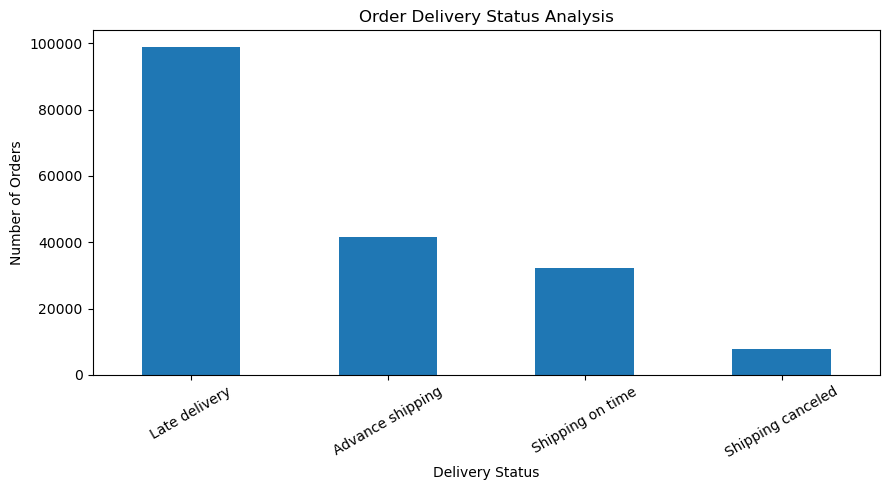

In [7]:
plt.figure(figsize=(9, 5))

delivery_status.plot(kind='bar')

plt.title("Order Delivery Status Analysis")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
delivery_percentage = df['Delivery Status'].value_counts(normalize=True) * 100

print("Delivery Status Percentage:")
print(delivery_percentage.round(2))

Delivery Status Percentage:
Delivery Status
Late delivery        54.83
Advance shipping     23.04
Shipping on time     17.84
Shipping canceled     4.30
Name: proportion, dtype: float64


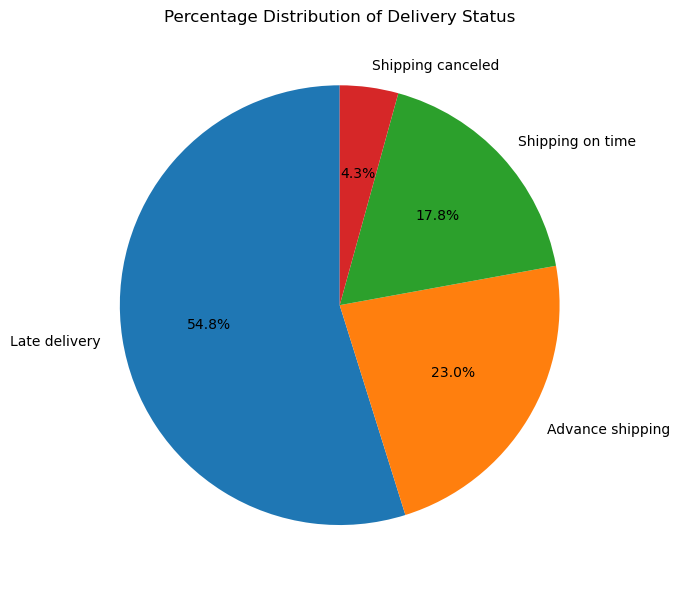

In [9]:
plt.figure(figsize=(8, 6))

plt.pie(
    delivery_percentage,
    labels=delivery_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage Distribution of Delivery Status")
plt.tight_layout()
plt.show()

In [10]:
# Calculate delivery delay in days
df['Delivery_Delay'] = (
    df['Days for shipping (real)'] -
    df['Days for shipment (scheduled)']
)

print("Delivery delay calculated successfully!")

Delivery delay calculated successfully!


In [11]:
region_delay = df.groupby('Order Region')['Delivery_Delay'].mean()

region_delay = region_delay.sort_values(ascending=False)

print("Average Delivery Delay by Region:")
print(region_delay.round(2))

Average Delivery Delay by Region:
Order Region
Central Asia       0.65
Central Africa     0.64
South Asia         0.60
Western Europe     0.60
US Center          0.59
East of USA        0.58
South of  USA      0.58
Eastern Europe     0.58
East Africa        0.57
West Asia          0.57
Eastern Asia       0.57
Central America    0.56
Southeast Asia     0.56
West of USA        0.56
South America      0.56
Oceania            0.56
North Africa       0.55
West Africa        0.55
Northern Europe    0.55
Caribbean          0.55
Southern Europe    0.52
Southern Africa    0.48
Canada             0.39
Name: Delivery_Delay, dtype: float64


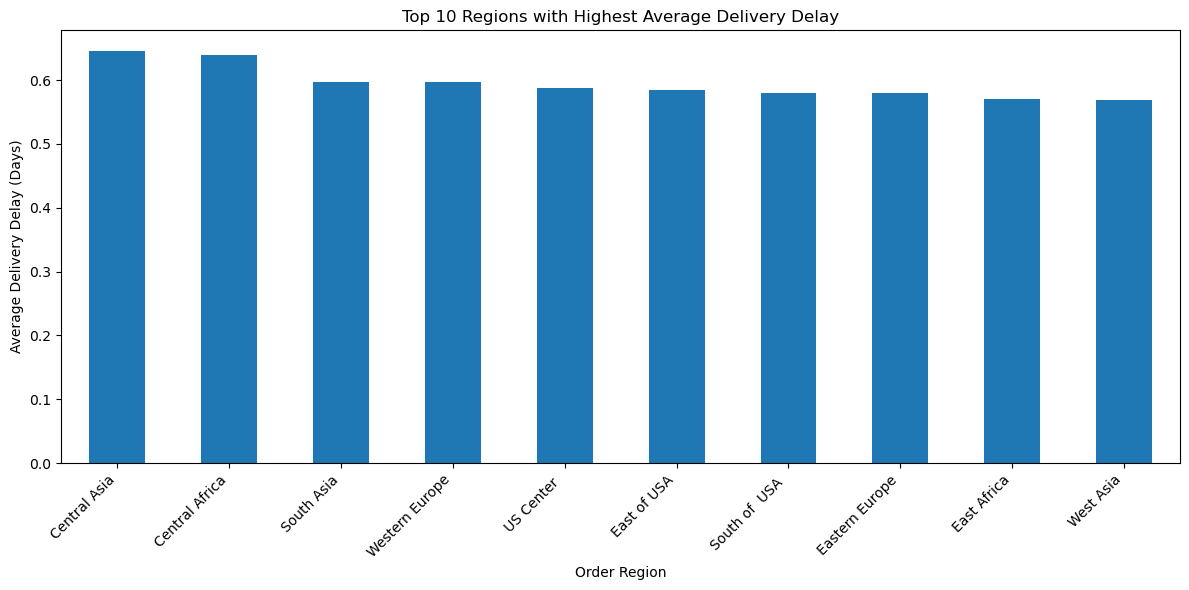

In [12]:
top_10_regions = region_delay.head(10)

plt.figure(figsize=(12, 6))

top_10_regions.plot(kind='bar')

plt.title("Top 10 Regions with Highest Average Delivery Delay")
plt.xlabel("Order Region")
plt.ylabel("Average Delivery Delay (Days)")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [13]:
region_analysis = df.groupby('Order Region').agg(
    Total_Orders=('Order Id', 'count'),
    Delayed_Orders=('Delivery_Delay', lambda x: (x > 0).sum()),
    Average_Delay=('Delivery_Delay', 'mean')
)

region_analysis['Delayed_Percentage'] = (
    region_analysis['Delayed_Orders'] /
    region_analysis['Total_Orders']
) * 100

region_analysis = region_analysis.sort_values(
    by='Delayed_Percentage',
    ascending=False
)

region_analysis.head(10).round(2)

,Total_Orders,Delayed_Orders,Average_Delay,Delayed_Percentage
Order Region,,,,
Central Africa,1677,1018,0.64,60.70
Western Europe,27109,15863,0.60,58.52
South Asia,7731,4523,0.60,58.50
South of USA,4045,2350,0.58,58.10
Southeast Asia,9539,5531,0.56,57.98
East of USA,6915,4009,0.58,57.98
West Asia,6009,3455,0.57,57.50
East Africa,1852,1064,0.57,57.45
Eastern Europe,3920,2252,0.58,57.45


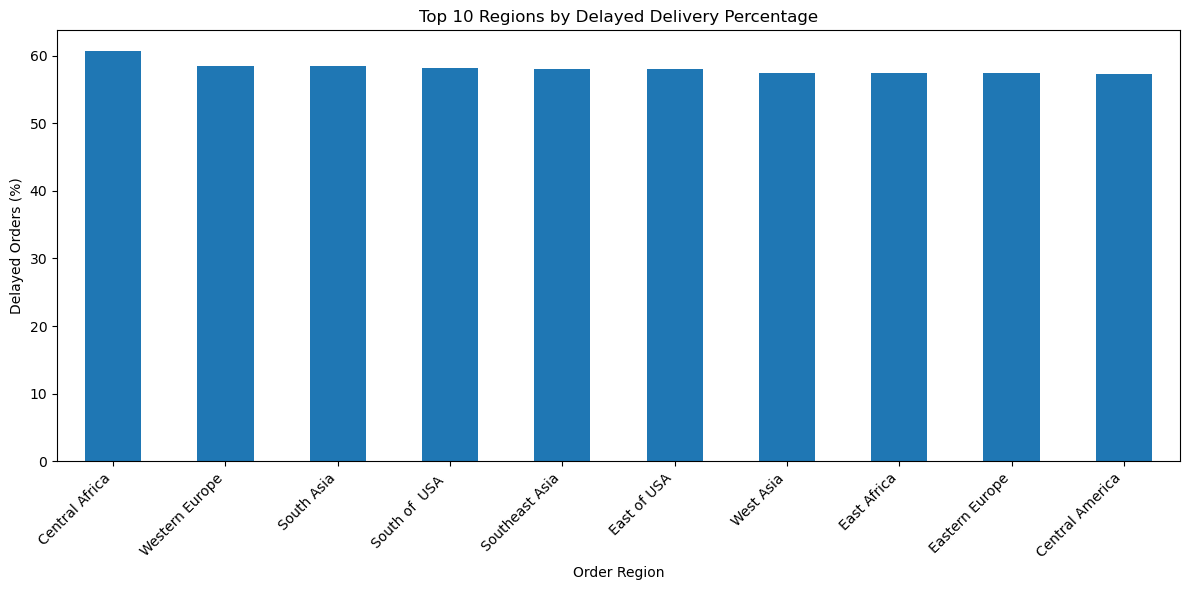

In [14]:
top_10_delay = region_analysis.head(10)

plt.figure(figsize=(12, 6))

top_10_delay['Delayed_Percentage'].plot(kind='bar')

plt.title("Top 10 Regions by Delayed Delivery Percentage")
plt.xlabel("Order Region")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
shipping_analysis = df.groupby('Shipping Mode').agg(
    Total_Orders=('Order Id', 'count'),
    Delayed_Orders=('Delivery_Delay', lambda x: (x > 0).sum()),
    Average_Delay=('Delivery_Delay', 'mean')
)

shipping_analysis['Delayed_Percentage'] = (
    shipping_analysis['Delayed_Orders'] /
    shipping_analysis['Total_Orders']
) * 100

shipping_analysis = shipping_analysis.sort_values(
    by='Delayed_Percentage',
    ascending=False
)

shipping_analysis.round(2)

,Total_Orders,Delayed_Orders,Average_Delay,Delayed_Percentage
Shipping Mode,,,,
First Class,27814,27814,1.00,100.00
Second Class,35216,28078,1.99,79.73
Same Day,9737,4657,0.48,47.83
Standard Class,107752,42851,-0.00,39.77


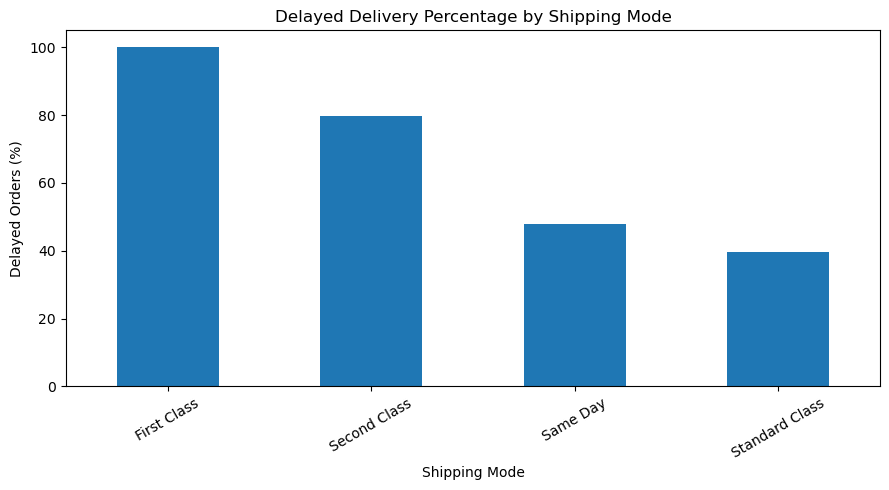

In [16]:
plt.figure(figsize=(9, 5))

shipping_analysis['Delayed_Percentage'].plot(kind='bar')

plt.title("Delayed Delivery Percentage by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [17]:
category_analysis = df.groupby('Category Name').agg(
    Total_Orders=('Order Id', 'count'),
    Delayed_Orders=('Delivery_Delay', lambda x: (x > 0).sum()),
    Average_Delay=('Delivery_Delay', 'mean')
)

category_analysis['Delayed_Percentage'] = (
    category_analysis['Delayed_Orders'] /
    category_analysis['Total_Orders']
) * 100

category_analysis = category_analysis.sort_values(
    by='Delayed_Percentage',
    ascending=False
)

category_analysis.round(2)

,Total_Orders,Delayed_Orders,Average_Delay,Delayed_Percentage
Category Name,,,,
Golf Bags & Carts,61,42,0.77,68.85
Lacrosse,343,213,0.66,62.10
Cameras,592,367,0.65,61.99
Pet Supplies,492,302,0.71,61.38
Sporting Goods,357,214,0.62,59.94
Basketball,67,40,0.48,59.70
Fitness Accessories,309,184,0.61,59.55
Crafts,484,288,0.63,59.50
Strength Training,111,66,0.67,59.46


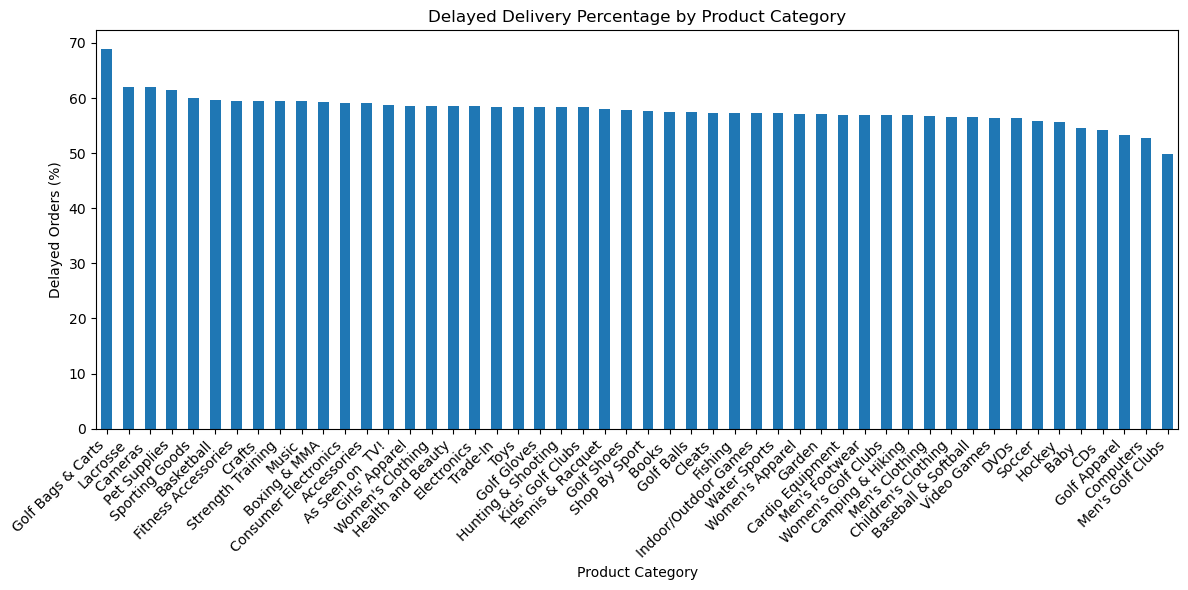

In [18]:
plt.figure(figsize=(12, 6))

category_analysis['Delayed_Percentage'].plot(kind='bar')

plt.title("Delayed Delivery Percentage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [20]:
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'],
    format='mixed',
    errors='coerce'
)

print(df['order date (DateOrders)'].dtype)

datetime64[ns]


In [21]:
df['Order_Month'] = df['order date (DateOrders)'].dt.month

df['Order_Year'] = df['order date (DateOrders)'].dt.year

print("Month and Year columns created successfully!")

Month and Year columns created successfully!


In [22]:
df[['order date (DateOrders)', 'Order_Month', 'Order_Year']].head()

,order date (DateOrders),Order_Month,Order_Year
0,2018-01-31 22:56:00,1,2018
1,2018-01-13 12:27:00,1,2018
2,2018-01-13 12:06:00,1,2018
3,2018-01-13 11:45:00,1,2018
4,2018-01-13 11:24:00,1,2018


In [23]:
monthly_analysis = df.groupby(
    ['Order_Year', 'Order_Month']
).agg(
    Total_Orders=('Order Id', 'count'),
    Delayed_Orders=('Delivery_Delay', lambda x: (x > 0).sum()),
    Average_Delay=('Delivery_Delay', 'mean')
)

monthly_analysis['Delayed_Percentage'] = (
    monthly_analysis['Delayed_Orders'] /
    monthly_analysis['Total_Orders']
) * 100

monthly_analysis.round(2)

Total_Orders  Delayed_Orders  Average_Delay  \
Order_Year Order_Month                                                
2015       1                    5322            2977           0.54   
           2                    4729            2739           0.60   
           3                    5362            3068           0.57   
           4                    5126            2893           0.55   
           5                    5357            3111           0.56   
           6                    5134            2889           0.54   
           7                    5299            3052           0.57   
           8                    5273            3066           0.60   
           9                    5140            3025           0.58   
           10                   5302            3028           0.54   
           11                   5235            2953           0.56   
           12                   5371            3076           0.57   
2016       1                    5317            3081           0.60   
           2                    4894            2757           0.55   
           3                    5210            3010           0.56   
           4                    5097            2918           0.58   
           5                    5302            3074           0.59   
           6                    5054            2977           0.64   
           7                    5305            2928           0.53   
           8                    5334            3039           0.52   
           9                    5160            2933           0.57   
           10                   5398            3073           0.57   
           11                   5210            2966           0.58   
           12                   5269            3085           0.55   
2017       1                    5217            2920           0.54   
           2                    4906            2823           0.59   
           3                    5347            3089           0.56   
           4                    5212            2943           0.57   
           5                    5317            3022           0.54   
           6                    4951            2772           0.52   
           7                    5318            3100           0.58   
           8                    5305            3108           0.61   
           9                    5189            2973           0.53   
           10                   2255            1264           0.54   
           11                   2055            1187           0.58   
           12                   2124            1235           0.58   
2018       1                    2123            1246           0.61   

                        Delayed_Percentage  
Order_Year Order_Month                      
2015       1                         55.94  
           2                         57.92  
           3                         57.22  
           4                         56.44  
           5                         58.07  
           6                         56.27  
           7                         57.60  
           8                         58.15  
           9                         58.85  
           10                        57.11  
           11                        56.41  
           12                        57.27  
2016       1                         57.95  
           2                         56.33  
           3                         57.77  
           4                         57.25  
           5                         57.98  
           6                         58.90  
           7                         55.19  
           8                         56.97  
           9                         56.84  
           10                        56.93  
           11                        56.93  
           12                        58.55  
2017       1                         55.97  
           2                         57

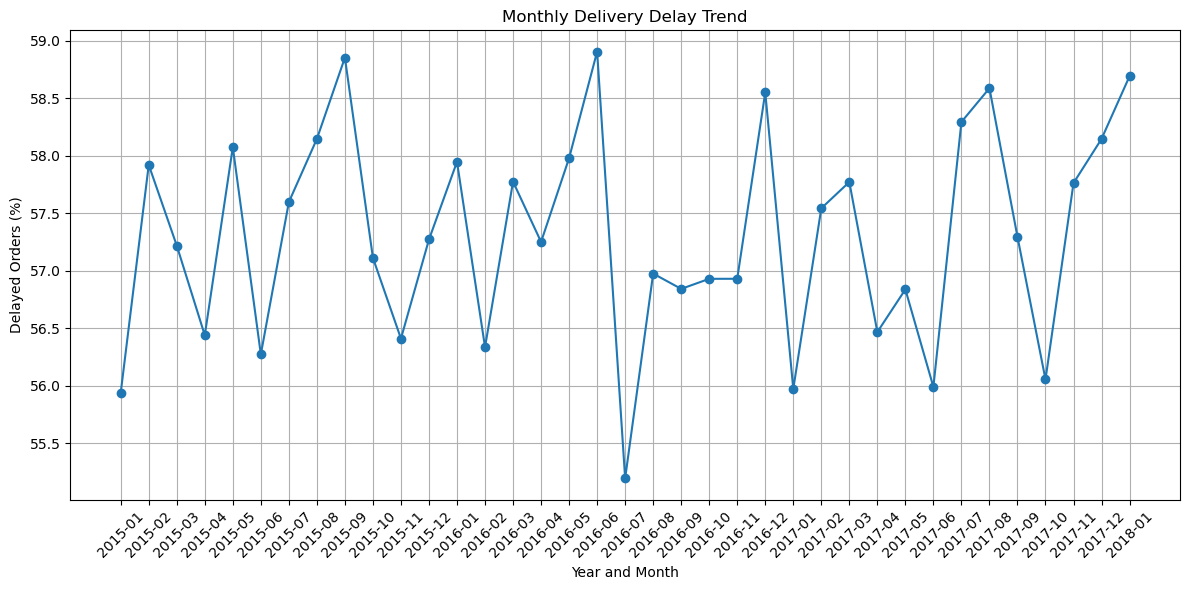

In [24]:
plt.figure(figsize=(12, 6))

monthly_analysis['Delayed_Percentage'].plot(
    kind='line',
    marker='o'
)

plt.title("Monthly Delivery Delay Trend")
plt.xlabel("Year and Month")
plt.ylabel("Delayed Orders (%)")

plt.xticks(
    range(len(monthly_analysis)),
    [f"{year}-{month:02d}" for year, month in monthly_analysis.index],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
worst_months = monthly_analysis.sort_values(
    by='Delayed_Percentage',
    ascending=False
)

print("Top 5 Months with Highest Delivery Delays:")

worst_months.head(5).round(2)

Top 5 Months with Highest Delivery Delays:


,,Total_Orders,Delayed_Orders,Average_Delay,Delayed_Percentage
Order_Year,Order_Month,,,,
2016,6,5054,2977,0.64,58.90
2015,9,5140,3025,0.58,58.85
2018,1,2123,1246,0.61,58.69
2017,8,5305,3108,0.61,58.59
2016,12,5269,3085,0.55,58.55


In [26]:
print("========== WEEK 3 BUSINESS INSIGHTS ==========")

print("\n1. Overall Delivery Status:")
print(df['Delivery Status'].value_counts())

print("\n2. Top 5 Regions with Highest Delayed Percentage:")
print(region_analysis[['Delayed_Orders', 'Delayed_Percentage']].head(5).round(2))

print("\n3. Shipping Mode Performance:")
print(shipping_analysis.round(2))

print("\n4. Top 5 Product Categories with Highest Delays:")
print(category_analysis[['Delayed_Orders', 'Delayed_Percentage']].head(5).round(2))

print("\n5. Top 5 Months with Highest Delivery Delays:")
print(worst_months.head(5).round(2))

print("\n========== ANALYSIS COMPLETED ==========")

========== WEEK 3 BUSINESS INSIGHTS ==========

1. Overall Delivery Status:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

2. Top 5 Regions with Highest Delayed Percentage:
                Delayed_Orders  Delayed_Percentage
Order Region                                      
Central Africa            1018               60.70
Western Europe           15863               58.52
South Asia                4523               58.50
South of  USA             2350               58.10
Southeast Asia            5531               57.98

3. Shipping Mode Performance:
                Total_Orders  Delayed_Orders  Average_Delay  \
Shipping Mode                                                 
First Class            27814           27814           1.00   
Second Class           35216           28078           1.99   
Same Day                9737            4657           0.48   
Standard Class      